<a href="https://colab.research.google.com/github/Malik-Nauman-Rauf-207/control-systems-book/blob/main/CIMID_Chapter3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐾 Chapter 3: The Engineer’s Toolbox: Python & MATLAB/Octave Lab

Welcome to Vector's Digital Workshop!

In Chapter 3, we turn our mathematical rules of change into working computer programs using **Python** and **MATLAB (GNU Octave)** . In this interactive notebook, you can run and edit **both** languages right in your browser!

* **🐍 Python cells** run natively.
* **🚀 MATLAB / GNU Octave cells** begin with the magic line `%%octave` at the very top of the cell.

### ⚙️ Step 0: Unlock the Workshop Tools
**Click the "Play" [▶] button on the code cell below first!** It will load all our Python libraries (`numpy`, `scipy`, `sympy`, `control`) and install the GNU Octave engine so you can run MATLAB code right inside this notebook . *(Note: This initial setup takes about 45–60 seconds to finish—perfect time for a quick stretch!)*

_NOTE: You Might get some error with `pip`, just ignore._

In [ ]:
# --- 🛠️ WORKSHOP SETUP: RUN THIS CELL FIRST! 🛠️ ---
import subprocess, tempfile, os, glob
from IPython.core.magic import register_cell_magic
from IPython.display import Image, display

print("⏳ Installing Python Control library & GNU Octave engine (takes ~35 seconds)...")

# 1. Install python-control cleanly (no oct2py needed, so ZERO ipykernel conflicts!)
subprocess.run(["pip", "install", "-q", "control", "sympy"], check=True)

# 2. Install GNU Octave and its Control & Symbolic toolboxes silently
subprocess.run("apt-get update -qq && apt-get install -y -qq octave octave-control octave-symbolic gnuplot",
               shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

# 3. Register a rock-solid %%octave cell magic that supports fprintf() AND inline plots!
@register_cell_magic
def octave(line, cell):
    with tempfile.TemporaryDirectory() as tmpdir:
        script_path = os.path.join(tmpdir, "script.m")
        plot_pattern = os.path.join(tmpdir, "fig_%d.png")

        # Configure Octave for headless plotting + immediate stdout flushing
        header = (
            "warning('off', 'all');\n"
            "graphics_toolkit('gnuplot');\n"
            "set(0, 'defaultfigurevisible', 'off');\n"
            "page_screen_output(0);\n"
            "page_output_immediately(1);\n"
        )
        # Save any open figures at the end of the cell so Colab can display them
        footer = f"""
        figs = get(0, 'children');
        for k = 1:numel(figs)
            print(figs(k), sprintf('{tmpdir}/fig_%d.png', k), '-dpng', '-r150');
        end
        """
        with open(script_path, "w") as f:
            f.write(header + "\n" + cell + "\n" + footer)

        proc = subprocess.run(
            ["octave-cli", "--no-gui", "-q", script_path],
            capture_output=True, text=True
        )
        if proc.stdout:
            print(proc.stdout, end="")
        if proc.stderr:
            print(proc.stderr, end="")

        for img_path in sorted(glob.glob(os.path.join(tmpdir, "fig_*.png"))):
            display(Image(filename=img_path))

# 4. Load standard Python libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import sympy as sp
import control as ct
import ipywidgets as widgets

print("✅ Workshop Ready! Both Python and MATLAB/Octave (%%octave) are unlocked!")

⏳ Installing Python Control library & GNU Octave engine (takes ~35 seconds)...
✅ Workshop Ready! Both Python and MATLAB/Octave (%%octave) are unlocked!


---
## 📝 Vector's Pocket Puzzle 1: A New Leak (Variables & Arithmetic)

Vector’s tank starts with `10.0` liters . His pump adds `3.0` L/min, but a sudden crack increases the leak to **`4.0` L/min**!  What will happen over the next half-minute (`dt = 0.5`)?

Run or modify the **Python** cell or the **MATLAB / Octave** cell below to calculate the new water level and see if the tank gains or loses water .

In [ ]:
# --- 🐍 PYTHON WORKSPACE: POCKET PUZZLE 1 ---
water = 10.0
pump_rate = 3.0
leak_rate = 4.0      # Try changing this!
dt = 0.5             # Half a minute

# 1. Calculate net rate of change
net_rate = pump_rate - leak_rate

# 2. Calculate next water amount
water_next = water + net_rate * dt

# 3. Print your answers!
print("--- 🐍 PYTHON OUTPUT ---")
print(f"Net Rate: {net_rate} L/min")
print(f"Next Water Amount: {water_next} liters")

if net_rate < 0:
    print("Status: The tank is losing water!")
elif net_rate > 0:
    print("Status: The tank is gaining water!")
else:
    print("Status: Water level is steady.")

--- 🐍 PYTHON OUTPUT ---
Net Rate: -1.0 L/min
Next Water Amount: 9.5 liters
Status: The tank is losing water!


In [ ]:
%%octave
% --- 🚀 MATLAB / OCTAVE WORKSPACE: POCKET PUZZLE 1 ---
water = 10.0;
pump_rate = 3.0;
leak_rate = 4.0;      % Try changing this!
dt = 0.5;             % Half a minute

% 1. Calculate the net rate:
net_rate = pump_rate - leak_rate;

% 2. Calculate next water amount:
water_next = water + net_rate * dt;

% 3. Display your results:
fprintf('--- 🚀 MATLAB / OCTAVE OUTPUT ---\n');
fprintf('Net Rate: %.1f liters/min\n', net_rate);
fprintf('Next Water Amount: %.1f liters\n', water_next);

if net_rate < 0
    fprintf('Status: The tank is losing water!\n');
elseif net_rate > 0
    fprintf('Status: The tank is gaining water!\n');
else
    fprintf('Status: Water level is steady.\n');
end

--- 🚀 MATLAB / OCTAVE OUTPUT ---
Net Rate: -1.0 liters/min
Next Water Amount: 9.5 liters
Status: The tank is losing water!


---
## 📝 Vector's Pocket Puzzle 2: The Repeat Button (Loops)

A `for` loop repeats instructions so Vector doesn't have to type the same line 6,000 times !
Experiment with the loop below:
1. Try changing `steps` between `5` and `3` .
2. Try changing `change` between `+2.0` (adding) and `-2.0` (subtracting) .

In [ ]:
# --- 🐍 PYTHON WORKSPACE: POCKET PUZZLE 2 ---
water = 10.0
steps = 3          # Try 5 steps vs. 3 steps
change = -2.0      # Try +2.0 (adding) vs. -2.0 (subtracting)

print(f"Starting amount: {water:.1f} liters")
print("-" * 32)

for step in range(steps):
    water = water + change
    print(f"After step {step + 1}: {water:.1f} liters")

print("-" * 32)
print(f"Final tank amount: {water:.1f} liters")

Starting amount: 10.0 liters
--------------------------------
After step 1: 8.0 liters
After step 2: 6.0 liters
After step 3: 4.0 liters
--------------------------------
Final tank amount: 4.0 liters


In [ ]:
%%octave
% --- 🚀 MATLAB / OCTAVE WORKSPACE: POCKET PUZZLE 2 ---
water = 10.0;
steps = 3;          % Try 5 steps vs. 3 steps
change = -2.0;      % Try +2.0 (adding) vs. -2.0 (subtracting)

fprintf('Starting amount: %.1f liters\n', water);
fprintf('--------------------------------\n');

for step = 1:steps
    water = water + change;
    fprintf('After step %d: %.1f liters\n', step, water);
end

fprintf('--------------------------------\n');
fprintf('Final tank amount: %.1f liters\n', water);

Starting amount: 10.0 liters
--------------------------------
After step 1: 8.0 liters
After step 2: 6.0 liters
After step 3: 4.0 liters
--------------------------------
Final tank amount: 4.0 liters


---
## 🌱 Lab 1: Program the Greenhouse Soil Simulator Yourself

Before handing a job to a fancy solver, let's build our own simulator from scratch using the Euler method !
We model the **Greenhouse Soil Moisture** where water loss grows in proportion to how wet the soil currently is :
$$\frac{dM}{dt} = u - kM, \qquad M(0) = 15$$

* $M$ is the soil moisture percentage (starting at `15.0`%) .
* $u = 8.0$ (% per hour added by the sprinkler) .
* $k = 0.2$ (the drainage/evaporation factor per hour) .
* Simulate **20 steps** using a time step of half an hour ($\Delta t = 0.5$) .

The Euler update rule for each step is :
$$M_{\text{next}} = M_{\text{current}} + (u - k M_{\text{current}})\Delta t$$

**Your Mission:** Fill in the missing variable declarations and write the `for` loop in either Python or MATLAB/Octave below !

### 🛠️ Mess with the Code (After you get it working!):
1. Set `moisture_initial = 40.0` (right at the equilibrium balance point where $u = kM$) . Predict the graph before running!
2. Set `u_pump = 0.0` and start with wet soil at `moisture_initial = 60.0` .
3. Use `dt = 0.25` and `number_of_steps = 40` .

In [ ]:
# --- 🐍 PYTHON SANDBOX: LAB 1 (lab01_soil.py) ---

# --- 🛠️ STEP 1: DECLARE YOUR VARIABLES 🛠️ ---
moisture_initial = None  # Set to 15.0 (%)
u_pump = None            # Set to 8.0 (%/hr)
k_loss = None            # Set to 0.2 (1/hr)
dt = None                # Set to 0.5 (hours)
number_of_steps = None   # Set to 20

if None in (moisture_initial, u_pump, k_loss, dt, number_of_steps):
    print("⚠️ Mission Incomplete: Replace all 'None' placeholders in Step 1 with numbers!")
else:
    time = np.arange(number_of_steps + 1) * dt
    moisture = np.zeros(number_of_steps + 1)
    moisture[0] = moisture_initial

    # --- 🛠️ STEP 2: WRITE YOUR FOR LOOP 🛠️ ---
    # Loop 'i' through range(number_of_steps):
    #   1. Calculate rate = u_pump - k_loss * moisture[i]
    #   2. Update moisture[i + 1] = moisture[i] + rate * dt

    # Write your for-loop right below this line:


    # --- PLOTTING CODE (KEEP INTACT) ---
    if np.all(moisture[1:] == 0):
        print("⚠️ Almost there! Write the 'for' loop in Step 2 so moisture updates at each step.")
    else:
        print(f"✅ Simulation Complete! Final soil moisture: {moisture[-1]:.2f} %")
        plt.figure(figsize=(7, 4))
        plt.plot(time, moisture, "o-", color="#0077CC", linewidth=2, label="Soil Moisture (%)")
        if k_loss > 0:
            plt.axhline(u_pump / k_loss, color="green", linestyle="--", label="Equilibrium (u/k)")
        plt.xlabel("Time (hours)")
        plt.ylabel("Moisture (%)")
        plt.title("Vector's Greenhouse Soil Moisture")
        plt.grid(True, linestyle=":", alpha=0.6)
        plt.legend()
        plt.tight_layout()
        plt.show()

In [ ]:
%%octave
% --- 🚀 MATLAB / OCTAVE SANDBOX: LAB 1 (lab01_soil.m) ---
% Replace the ___ placeholders below with your code and run!

% --- 🛠️ STEP 1: DECLARE YOUR VARIABLES 🛠️ ---
moisture_initial = ___ ; % Set to 15.0 (%)
u_pump = ___ ;           % Set to 8.0 (%/hr)
k_loss = ___ ;           % Set to 0.2 (1/hr)
dt = ___ ;               % Set to 0.5 (hours)
number_of_steps = ___ ;  % Set to 20

time = (0:number_of_steps) * dt;
moisture = zeros(1, number_of_steps + 1);
moisture(1) = moisture_initial;

% --- 🛠️ STEP 2: WRITE YOUR FOR LOOP 🛠️ ---
% Write a for loop from i = 1:number_of_steps
for i = ___ : ___
    rate = ___ ;                  % Calculate u_pump - k_loss * moisture(i)
    moisture(i + 1) = ___ ;       % Update moisture(i) + rate * dt
end
% -----------------------------------------

fprintf('Final moisture: %.2f %%\n', moisture(end));

% --- PLOTTING CODE (KEEP INTACT) ---
figure;
plot(time, moisture, 'o-', 'LineWidth', 2, 'DisplayName', 'Soil Moisture (%)');
hold on;
yline(u_pump / k_loss, 'g--', 'DisplayName', 'Equilibrium');
xlabel('Time (hours)');
ylabel('Moisture (%)');
title('Vector''s Greenhouse Soil Moisture');
grid on;
legend('show', 'Location', 'southeast');

---
## ☕ Lab 2: Let a Numerical Solver Follow the Cocoa (`solve_ivp` & `ode45`)

Let's model Vector's cooling mug of hot cocoa from Chapter 2 :
$$\frac{dT}{dt} = -k(T - T_{\text{room}}), \qquad T(0) = 80^\circ\text{C}$$
where $T_{\text{room}} = 20^\circ\text{C}$ and $k = 0.1\text{ min}^{-1}$ .

**Your Coding Challenge:**
1. Call the professional ODE solver (`solve_ivp` in Python or `ode45` in MATLAB/Octave) .
2. Write your own hand-built Euler `for` loop (with a chunky step $\Delta t = 5.0$ minutes) to compare against the solver .
3. Write the plotting commands to compare both curves on the same graph !

### 🛠️ Mess with the Code (After you get it working!):
1. **Put the cocoa in the fridge:** Change `room_temperature = 20.0` to `4.0` .
2. **Make it iced cocoa:** Set `initial_temperature = 10.0` and put `room_temperature` back to `20.0` .
3. **Shrink the Euler step:** Change `dt = 5.0` and `euler_steps = 6` to `dt = 1.0` and `euler_steps = 30` .

In [ ]:
# --- 🐍 PYTHON SANDBOX: LAB 2 (lab02_cocoa.py) ---

room_temperature = 20.0   # degrees C
cooling_rate = 0.1        # per minute
initial_temperature = 80.0
sample_times = np.linspace(0.0, 30.0, 301)

def cocoa_rate(t, state):
    temperature = state[0]
    return [-cooling_rate * (temperature - room_temperature)]

# --- 🛠️ STEP 1: CALL solve_ivp 🛠️ ---
# Pass: cocoa_rate, (0.0, 30.0), [initial_temperature], t_eval=sample_times
solution = None

# --- 🛠️ STEP 2: WRITE AN EULER LOOP TO COMPARE 🛠️ ---
dt = 5.0
euler_steps = 6
euler_time = np.arange(euler_steps + 1) * dt
euler_temp = np.zeros(euler_steps + 1)
euler_temp[0] = initial_temperature

# Write a 'for' loop for i in range(euler_steps):
#   rate = -cooling_rate * (euler_temp[i] - room_temperature)
#   euler_temp[i + 1] = euler_temp[i] + rate * dt


# --- 🛠️ STEP 3: PLOT YOUR RESULTS 🛠️ ---
if solution is None or np.all(euler_temp[1:] == 0):
    print("⚠️ Complete Step 1 (solve_ivp), Step 2 (Euler loop), and Step 3 (plotting)!")
else:
    temperature = solution.y[0]
    print(f"Solver final temp: {temperature[-1]:.2f} °C")
    print(f"Euler final temp:  {euler_temp[-1]:.2f} °C")

    plt.figure(figsize=(7, 4))
    # 1. Use plt.plot(solution.t, temperature, label="solve_ivp Solver")
    # 2. Use plt.plot(euler_time, euler_temp, "o--", label="Euler Loop (dt=5)")
    # 3. Add plt.xlabel("Time (minutes)") and plt.ylabel("Temperature (C)")
    # Write your plotting lines right below:


    plt.axhline(room_temperature, color="gray", linestyle=":", label="Room temp")
    plt.title("Vector's Cooling Cocoa: Solver vs. Loop")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

Solver final temp: 22.99 C
Euler final temp:  20.94 C


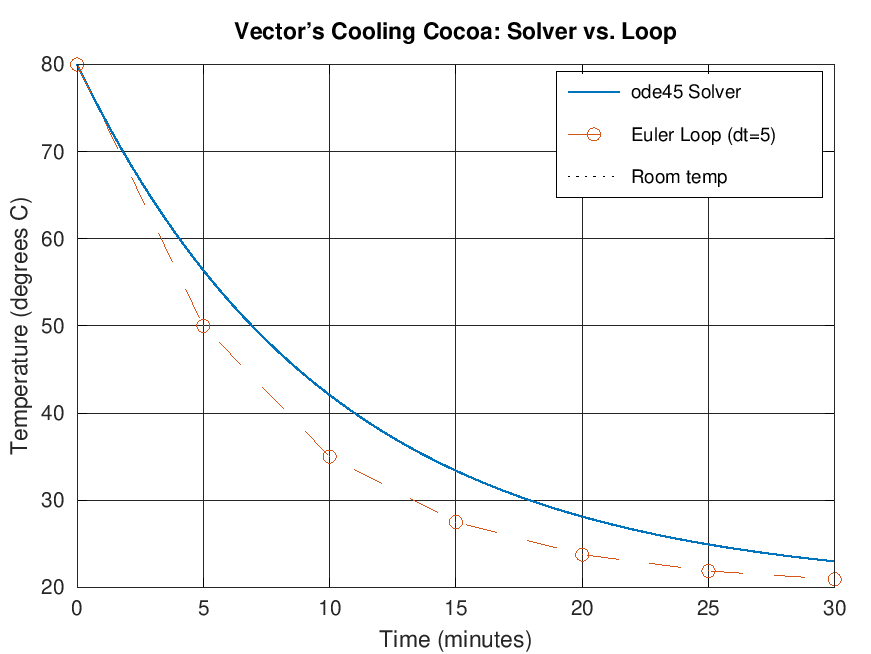

In [ ]:
%%octave
% --- 🚀 MATLAB / OCTAVE SANDBOX: LAB 2 (lab02_cocoa.m) ---

room_temperature = 20.0;  % degrees C
cooling_rate = 0.1;       % per minute
initial_temperature = 80.0;
sample_times = linspace(0.0, 30.0, 301);

% --- 🛠️ STEP 1: CALL ode45 🛠️ ---
% Call ode45 using @cocoa_rate, sample_times, and initial_temperature
[time, temperature] = ode45( ___ , ___ , ___ );

% --- 🛠️ STEP 2: WRITE AN EULER LOOP TO COMPARE 🛠️ ---
dt = 5.0;
euler_steps = 6;
euler_time = (0:euler_steps) * dt;
euler_temp = zeros(1, euler_steps + 1);
euler_temp(1) = initial_temperature;

for i = ___ : ___
    rate = -cooling_rate * (euler_temp(i) - room_temperature);
    euler_temp(i + 1) = ___ ;
end

fprintf('Solver final temp: %.2f C\n', temperature(end));
fprintf('Euler final temp:  %.2f C\n', euler_temp(end));

% --- 🛠️ STEP 3: WRITE THE PLOTTING CODE 🛠️ ---
figure;
% 1. Plot (time, temperature) using plot()
plot( ___ , ___ , 'LineWidth', 2, 'DisplayName', 'ode45 Solver');
hold on;
% 2. Plot (euler_time, euler_temp) with 'o--' style
plot( ___ , ___ , 'o--', 'LineWidth', 1.5, 'DisplayName', 'Euler Loop');
yline(room_temperature, '--', 'DisplayName', 'Room temp');

% 3. Add xlabel, ylabel, and title!
xlabel( ___ );
ylabel( ___ );
title( ___ );
grid on;
legend('show');

% --- TRADITIONAL RATE FUNCTION AT THE BOTTOM ---
function dTdt = cocoa_rate(t, T)
    room_temperature = 20.0;
    cooling_rate = 0.1;
    dTdt = -cooling_rate * (T - room_temperature);
end

---
## 🪄 Lab 3: Numerical Answers vs. Symbolic Answers (`sympy` & `dsolve`)

In Lab 2, the computer acted like a number-crunching calculator . Now let's ask the computer to act like a mathematician and solve for the **exact algebra formula** of Vector's cooling cocoa :
$$\frac{dT}{dt} = -\frac{1}{10}(T - 20), \qquad T(0) = 80$$

**Your Mission:** Complete Steps 1, 2, and 3 to declare the symbolic variables, write the differential equation, and call `dsolve` to discover the exact mathematical formula $T(t) = 20 + 60e^{-t/10}$ !

In [ ]:
# --- 🐍 PYTHON SANDBOX: LAB 3 (lab03_symbolic.py) ---

# --- 🛠️ STEP 1: DECLARE SYMBOLIC t AND FUNCTION T 🛠️ ---
# Set t = sp.symbols("t", real=True)
# Set T = sp.Function("T")
t = None
T = None

# --- 🛠️ STEP 2: WRITE THE DIFFERENTIAL EQUATION 🛠️ ---
# Set equation = sp.Eq(sp.diff(T(t), t), -sp.Rational(1, 10) * (T(t) - 20))
equation = None

# --- 🛠️ STEP 3: SOLVE WITH sp.dsolve 🛠️ ---
# Set solution = sp.dsolve(equation, T(t), ics={T(0): 80})
solution = None

# --- VERIFICATION & OUTPUT (KEEP INTACT) ---
if None in (t, T, equation, solution):
    print("⚠️ Complete Steps 1, 2, and 3 above to find the symbolic formula!")
else:
    print("✅ Exact Temperature Formula Found:")
    sp.pprint(solution)
    print("-" * 45)
    print("Exact temp at 30 min:", sp.N(solution.rhs.subs(t, 30), 8), "°C")

    residual = sp.simplify(
        sp.diff(solution.rhs, t) + (solution.rhs - 20) / 10
    )
    print("Equation check (should be 0):", residual)

In [ ]:
%%octave
% --- 🚀 MATLAB / OCTAVE SANDBOX: LAB 3 (lab03_symbolic.m) ---
pkg load symbolic
warning('off', 'all');

% --- 🛠️ STEP 1: DECLARE SYMBOLIC FUNCTION T(t) 🛠️ ---
syms ___

% --- 🛠️ STEP 2: WRITE THE DIFFERENTIAL EQUATION 🛠️ ---
% Write: diff(T, t) == -sym(1)/10 * (T - 20)
equation = ___ == ___ ;

% --- 🛠️ STEP 3: SET INITIAL CONDITION & SOLVE 🛠️ ---
% Set condition: T(0) == 80, then call dsolve(equation, condition)
condition = ___ ;
solution = dsolve( ___ , ___ );

% --- VERIFICATION & OUTPUT (KEEP INTACT) ---
disp('Temperature formula:');
disp(solution);
disp('At 30 min:');
disp(vpa(subs(solution, t, 30), 8));

residual = simplify(diff(solution, t) + (solution - 20)/10);
disp('Equation check (should be 0):');
disp(residual);

---
## 🎥 Lab 4 (Part 1 & Part 2): The Camera Chase & Control Toolbox

Let $x$ be the video-game camera position and $r = 10$ meters be the player's target position:
$$\frac{dx}{dt} = k(r - x), \qquad x(0) = 0, \qquad k = 0.8$$

In **Part 1**, we simulate the camera using `solve_ivp` / `ode45`.
In **Part 2**, we package the exact same camera into a **State-Space Control Model** ($A = -k, B = k, C = 1, D = 0$) using `python-control` (`ct.ss`) and MATLAB/Octave's Control System Toolbox (`ss`)!

In [ ]:
# --- 🐍 PYTHON SANDBOX: LAB 4 PART 1 (solve_ivp) & PART 2 (python-control) ---

camera_gain = 0.8  # per second
target = 10.0      # meters
sample_times = np.linspace(0.0, 10.0, 201)

# =========================================================
# PART 1: NUMERICAL SOLVER (solve_ivp)
# =========================================================
# --- 🛠️ STEP 1: DEFINE THE RATE FUNCTION 🛠️ ---
def camera_rate(t, state):
    camera = state[0]
    return [camera_gain * (target - camera)]

# --- 🛠️ STEP 2: CALL solve_ivp 🛠️ ---
solution = solve_ivp(
    camera_rate,
    (0.0, 10.0),
    [0.0],
    t_eval=sample_times,
    rtol=1e-7,
    atol=1e-9
)

# =========================================================
# PART 2: CONTROL SYSTEM TOOLBOX (python-control)
# =========================================================
# --- 🛠️ STEP 3: DEFINE STATE-SPACE COMPARTMENTS (A, B, C, D) 🛠️ ---
camera_system = ct.ss([[-camera_gain]], [[camera_gain]], [[1.0]], [[0.0]])
response = ct.step_response(camera_system, sample_times)
cam_control = target * np.asarray(response.outputs).reshape(-1)

# --- PLOTTING BOTH TO COMPARE ---
plt.figure(figsize=(7, 4))
plt.plot(solution.t, solution.y[0], color="#0077CC", linewidth=3, label="Part 1: solve_ivp")
plt.plot(response.time, cam_control, "--", color="#FF9A3C", linewidth=2.5, label="Part 2: python-control (ss)")
plt.axhline(target, color="gray", linestyle=":", label="Target (10m)")
plt.xlabel("Time (seconds)")
plt.ylabel("Position (meters)")
plt.title("Vector's Camera Chase: Solver vs. Control Toolbox")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
%%octave
% --- 🚀 MATLAB / OCTAVE SANDBOX: LAB 4 PART 1 (ode45) & PART 2 (Control Toolbox) ---
pkg load control

camera_gain = 0.8; % per second
target = 10.0;     % meters
sample_times = linspace(0.0, 10.0, 201);

% =========================================================
% PART 1: NUMERICAL SOLVER (ode45)
% =========================================================
camera_rate = @(t, camera) camera_gain * (target - camera);
options = odeset('RelTol', 1e-7, 'AbsTol', 1e-9);
[time_ode, camera_ode] = ode45(camera_rate, sample_times, 0.0, options);

% =========================================================
% PART 2: CONTROL SYSTEM TOOLBOX (ss & step)
% =========================================================
camera_system = ss(-camera_gain, camera_gain, 1, 0);
[unit_camera, time_ctrl] = step(camera_system, sample_times);
camera_ctrl = target * unit_camera;

% --- PLOTTING BOTH TO COMPARE ---
figure;
plot(time_ode, camera_ode, 'b-', 'LineWidth', 2.5);
hold on;
plot(time_ctrl, camera_ctrl, 'r--', 'LineWidth', 2);
plot(sample_times, target * ones(size(sample_times)), 'k:');
xlabel('Time (seconds)');
ylabel('Position (meters)');
title('Vector''s Camera Chase: ode45 vs. ss()');
legend('Part 1: ode45', 'Part 2: Control Toolbox (ss)', 'Target (10m)', 'Location', 'southeast');
grid on;

---
## 💥 A Workshop Challenge: When Big Time Steps Lie

In real life, our camera approaches the 10-meter target smoothly without *ever* passing it .
But what happens if we use a hand-built Euler loop and choose a huge time step ($\Delta t$) ?
$$x_{\text{next}} = x_{\text{current}} + k(r - x_{\text{current}})\Delta t$$

**Run the cell below and drag the `dt_slider` from `0.1` up to `3.0` seconds to watch the numerical simulation blow up!**

In [ ]:
def run_blowup_sim(dt=0.1):
    k = 0.8
    target = 10.0

    times = np.arange(0, 10 + dt, dt)
    camera = np.zeros_like(times)

    for i in range(len(times) - 1):
        camera[i+1] = camera[i] + k * (target - camera[i]) * dt

    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.plot(times, camera, 'o-', color='#CC2222', linewidth=2, label=f"Euler (Δt = {dt:.1f}s)")
    ax.axhline(target, color='gray', linestyle='--', linewidth=2, label="Target (10m)")
    ax.set_ylim(-5, max(15, np.max(camera) + 2))
    ax.set_title("When Big Time Steps Lie (Camera Euler Loop)", fontweight="bold")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Camera Position (m)")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend()
    plt.tight_layout()
    plt.show()

widgets.interact(
    run_blowup_sim,
    dt=widgets.FloatSlider(min=0.1, max=3.0, step=0.1, value=0.1, description='Time Step (Δt):')
);

---
## 🧠 Vector’s Brain Teasers (Interactive Scratchpad)

Try predicting the answer to each Brain Teaser from the book *before* testing it in the **Python** and **MATLAB / Octave** scratchpads below !

1. **The Greenhouse Soil Step:** $M(0) = 15.0\%$, $u = 8.0\%/\text{hr}$, $k = 0.2$, $\Delta t = 0.5\text{ hr}$ .
   * a. What is the net rate of change during the first step?
   * b. How much moisture is added/lost during the step?
   * c. What is the next moisture amount?
   * d. At what moisture percentage will the net rate equal zero?
2. **Assignment or Question?** Explain `moisture = 40` vs. `moisture == 40` .
3. **The Pump at the Boundary:** In `if moisture < target` (with `target = 50`), predict `pump_on` for `35`, `50`, and `65` . How do you change `<` so it turns on at *exactly* `50`?
4. **Three Repeats:** Start `moisture` at `10` . Add `3` inside a loop that runs three times . List the values after each update .
5. **Two Address Systems:** For `history = [15.0, 17.5, 19.5, 21.0]`, write the Python index and MATLAB index that retrieve the third item (`19.5`) .
6. **The Missing Half Hour:** A student writes `moisture_next = moisture + rate` with `dt = 0.5`, `moisture = 15.0`, and `rate = 5.0` . What does their buggy code produce vs. the true answer?
7. **A Flat Graph:** In Lab 1, set `moisture_initial = 40.0` . Does a flat graph mean no water is moving?
8. **The Correct Drawer:** Name one Python tool and one MATLAB tool for plotting, ODE solving, symbolic math, and state-space models .
9. **Cocoa at Balance:** Set initial cocoa temp to `20.0` °C (room temp) . What is the initial rate of change and graph shape?
10. **A Formula Check:** Using $T(t) = 20 + 60e^{-t/10}$, find $T(0)$ and what $T(t)$ approaches as $t \to \infty$ .
11. **A Camera That Jumps Too Far:** With $x = 0, r = 10, k = 0.8$, find the first Euler step for $\Delta t = 0.5$ and $\Delta t = 2.0$ .
12. **Repair Vector's Notebook:** Fix `values = [2, 3, 4]; answer = values ** 2` in Python (using NumPy) and in MATLAB/Octave (using `.^`) !

In [ ]:
# --- 🐍 PYTHON SCRATCHPAD FOR VECTOR'S BRAIN TEASERS ---

# Brain Teaser 1: Greenhouse Soil Step
M = 15.0
u = 8.0
k = 0.2
dt = 0.5
rate = u - k * M
M_next = M + rate * dt
print(f"BT 1 -> Net rate: {rate}%/hr | Change: {rate*dt}% | Next Moisture: {M_next}% | Equilibrium: {u/k}%")

# Brain Teaser 5: Two Address Systems (3rd item of [15.0, 17.5, 19.5, 21.0])
history = [15.0, 17.5, 19.5, 21.0]
print(f"BT 5 -> Third item in Python (index 2): {history[2]}")

# Brain Teaser 11: Camera Jump
x, r, k_cam = 0.0, 10.0, 0.8
print(f"BT 11 -> Camera step (dt=0.5): {x + k_cam*(r - x)*0.5} m | Camera step (dt=2.0): {x + k_cam*(r - x)*2.0} m")

# Brain Teaser 12: Repair Vector's Notebook with NumPy!
values = np.array([2, 3, 4])
answer = values ** 2
print(f"BT 12 -> Squared array in Python: {answer}")

# --- 🛠️ ADD YOUR OWN BRAIN TEASER TESTS BELOW! 🛠️ ---

In [ ]:
%%octave
% --- 🚀 MATLAB / OCTAVE SCRATCHPAD FOR VECTOR'S BRAIN TEASERS ---

% Brain Teaser 1: Greenhouse Soil Step
M = 15.0; u = 8.0; k = 0.2; dt = 0.5;
rate = u - k * M;
M_next = M + rate * dt;
fprintf('BT 1 -> Net rate: %.1f %%/hr | Change: %.2f %% | Next Moisture: %.2f %%\n', rate, rate*dt, M_next);

% Brain Teaser 5: Two Address Systems (3rd item in MATLAB is index 3!)
history = [15.0, 17.5, 19.5, 21.0];
fprintf('BT 5 -> Third item in MATLAB (index 3): %.1f\n', history(3));

% Brain Teaser 12: Repair Vector's Notebook with element-wise squaring (.^)!
values = [2, 3, 4];
answer = values .^ 2;
disp('BT 12 -> Squared array in MATLAB/Octave:');
disp(answer);

% --- 🛠️ ADD YOUR OWN BRAIN TEASER TESTS BELOW! 🛠️ ---